<a href="https://colab.research.google.com/github/YikeCahya/PCVK_Ganjil_2026/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama: Yulike Dwi Nurcahyani

NIM: 244107020146

Kelas: TI - 3E

Modul: 6

**D. PRAKTIKUM FILTER**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [3]:
# Fungsi konvolusi 2D kustom
def convolution2d(image, kernel, stride=1, padding=0):
    # Padding citra jika ditentukan
    if padding > 0:
        image_padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)
    else:
        image_padded = image.copy()

    i_h, i_w = image_padded.shape
    k_h, k_w = kernel.shape

    # Menghitung dimensi output
    out_h = int((i_h - k_h) / stride) + 1
    out_w = int((i_w - k_w) / stride) + 1

    output = np.zeros((out_h, out_w), dtype=np.float32)

    # Proses konvolusi / cross-correlation spasial
    for y in range(0, out_h):
        for x in range(0, out_w):
            y_start = y * stride
            y_end = y_start + k_h
            x_start = x * stride
            x_end = x_start + k_w

            region = image_padded[y_start:y_end, x_start:x_end]
            output[y, x] = np.sum(region * kernel)

    # Normalisasi/clipping nilai piksel ke rentang 0-255
    output = np.clip(output, 0, 255).astype(np.uint8)
    return output

# Load citra masukan dan ubah ke Grayscale
img = cv.imread('/content/drive/MyDrive/Kuliah/PCVK/Images/mandrill.tiff')
if img is None:
    # Menggunakan dummy image jika file tidak ditemukan
    img = np.random.randint(0, 256, (512, 512, 3), dtype=np.uint8)

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

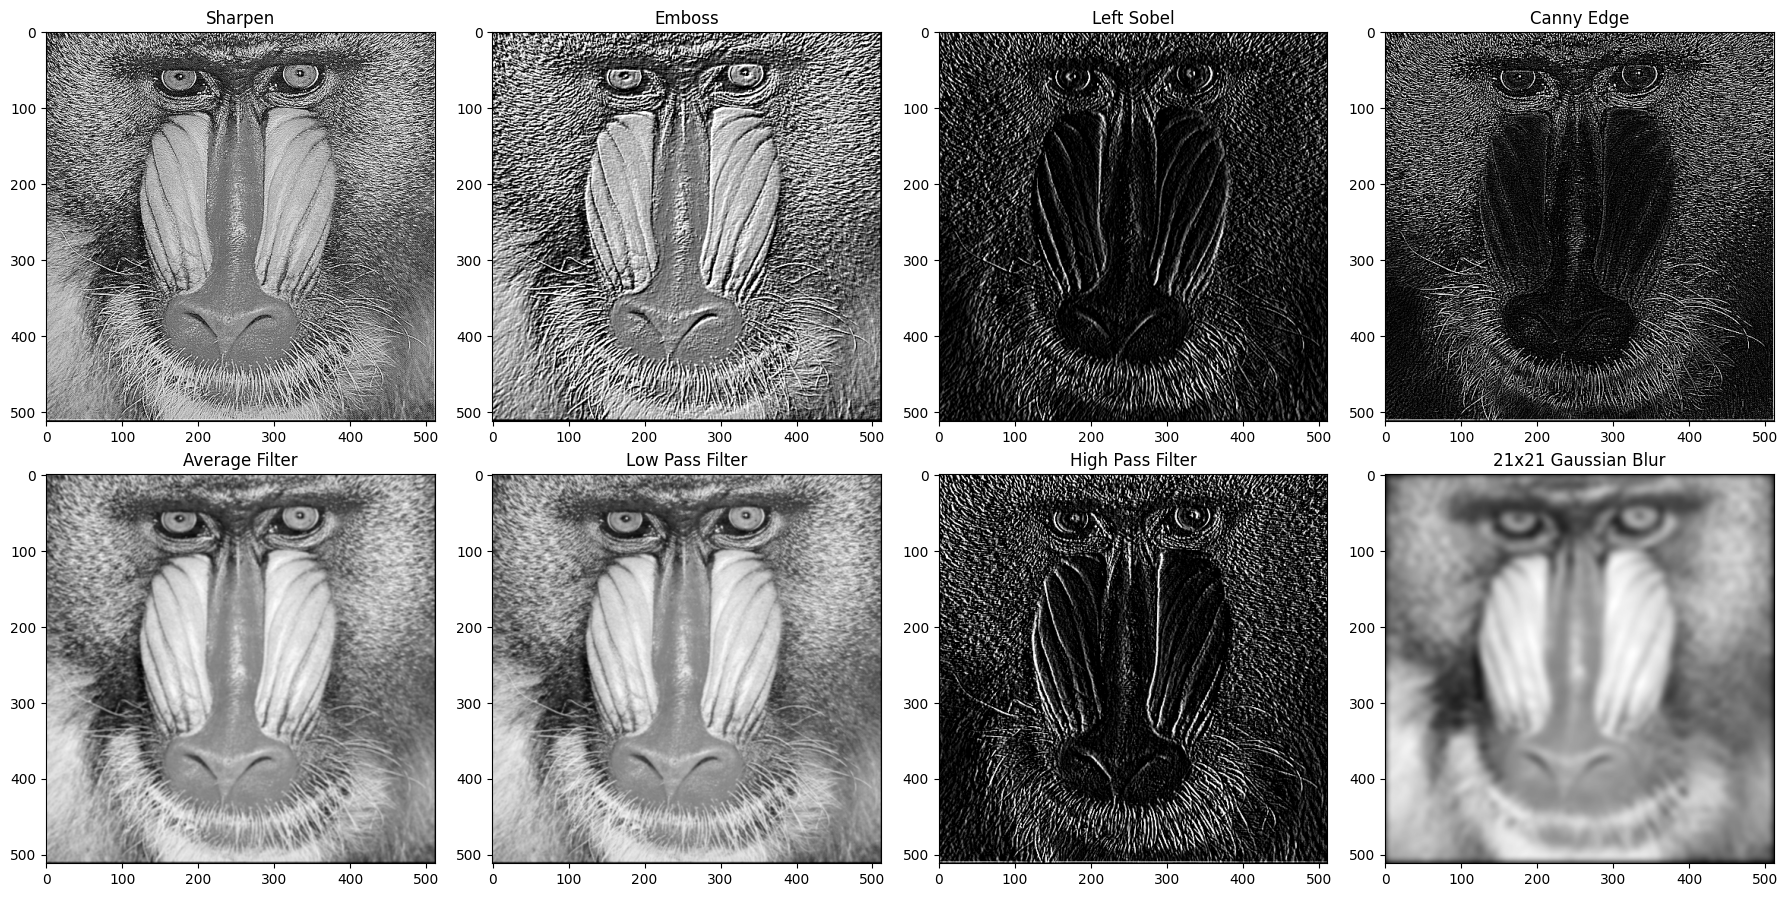

In [4]:
# Definisi Berbagai Kernel
# 1. Sharpen
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

# 2. Emboss
kernel_emboss = np.array([
    [-2, -1, 0],
    [-1,  1, 1],
    [ 0,  1, 2]
], dtype=np.float32)

# 3. Left Sobel Edge Detection
kernel_left_sobel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=np.float32)

# 4. Canny Edge Detection
kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

# 5. Average Filter 3x3
kernel_average = (1.0 / 9.0) * np.ones((3, 3), dtype=np.float32)

# 6. Low Pass Filter 3x3
kernel_lpf = (1.0 / 12.0) * np.array([
    [1, 1, 1],
    [1, 4, 1],
    [1, 1, 1]
], dtype=np.float32)

# 7. High Pass Filter 3x3
kernel_hpf = np.array([
    [-1, 0, 1],
    [-1, 0, 3],
    [-3, 0, 1]
], dtype=np.float32)

# 8. 21x21 Gaussian Blur Kernel Generator
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel_21 = gaussian_kernel_1d @ gaussian_kernel_1d.transpose()

# Eksekusi Konvolusi Manual
res_sharpen    = convolution2d(img_gray, kernel_sharpen, stride=1, padding=1)
res_emboss     = convolution2d(img_gray, kernel_emboss, stride=1, padding=1)
res_left_sobel = convolution2d(img_gray, kernel_left_sobel, stride=1, padding=1)
res_canny      = convolution2d(img_gray, kernel_canny, stride=1, padding=1)
res_average    = convolution2d(img_gray, kernel_average, stride=1, padding=1)
res_lpf        = convolution2d(img_gray, kernel_lpf, stride=1, padding=1)
res_hpf        = convolution2d(img_gray, kernel_hpf, stride=1, padding=1)
res_gauss21    = convolution2d(img_gray, gauss_kernel_21, stride=1, padding=10)

# Menampilkan Hasil
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
titles = [
    "Sharpen", "Emboss", "Left Sobel", "Canny Edge",
    "Average Filter", "Low Pass Filter", "High Pass Filter", "21x21 Gaussian Blur"
]
outputs = [
    res_sharpen, res_emboss, res_left_sobel, res_canny,
    res_average, res_lpf, res_hpf, res_gauss21
]

for ax, out, title in zip(axes.ravel(), outputs, titles):
    ax.imshow(out, cmap='gray')
    ax.set_title(title)
    ax.axis('on')
plt.tight_layout()
plt.show()

**E. FILTER LIBRARY DAN FILTER MODERN**

In [5]:
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img_item, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img_item.shape) == 2:
            plt.imshow(img_item, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(img_item, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

Percobaan 1: Filter Gaussian, Sharpen, dan Canny (OpenCV)

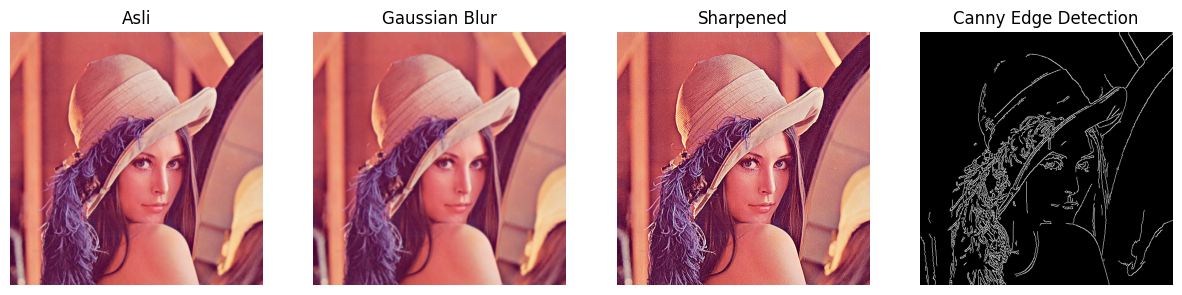

In [6]:
img_lena = cv.imread('/content/drive/MyDrive/Kuliah/PCVK/Images/Lenna.png')
if img_lena is None:
    img_lena = cv.cvtColor(img, cv.COLOR_GRAY2BGR) if len(img.shape)==2 else img.copy()

img_lena_gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img_lena, (7, 7), 1)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img_lena, -1, sharpen_kernel)
edges = cv.Canny(img_lena_gray, 100, 200)

show_side_by_side(
    [img_lena, blur, sharpened, edges],
    ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"]
)

Percobaan 2: Bilateral Filtering & Edge Preserving Filter

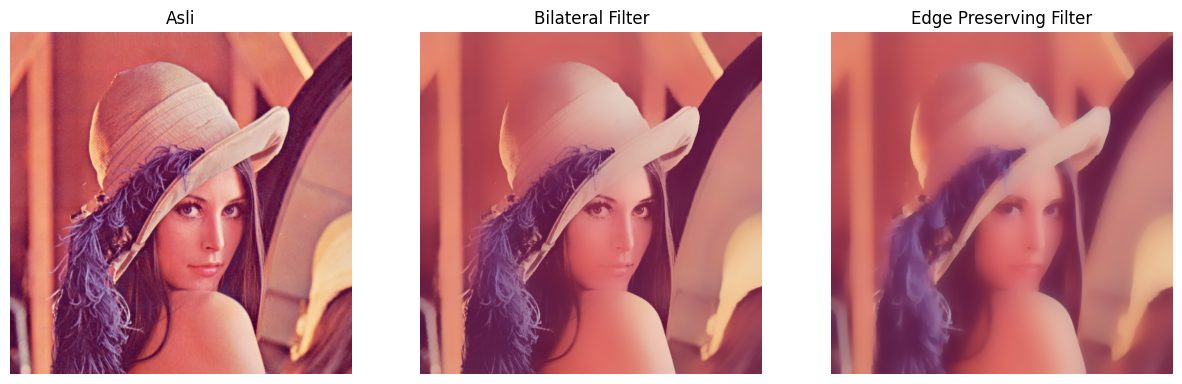

In [7]:
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img_lena, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img_lena, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side(
    [img_lena, bilateral, edge_preserve],
    ["Asli", "Bilateral Filter", "Edge Preserving Filter"]
)

Percobaan 3: Feature Map pada CNN (PyTorch)

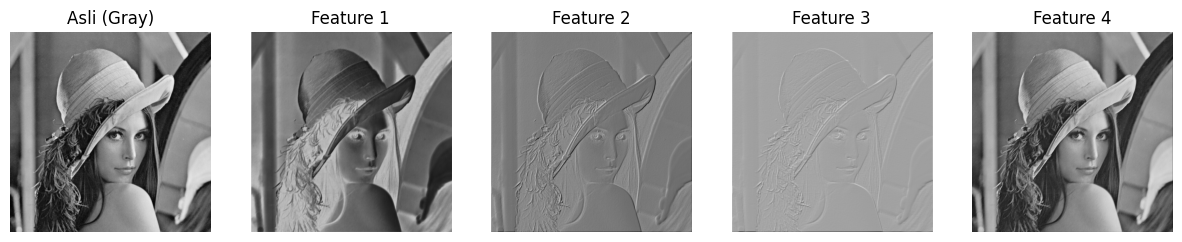

In [8]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah citra ke tensor
img_tensor = torch.tensor(img_lena_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Forward pass
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side(
    [img_lena_gray] + feature_maps,
    ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))]
)

Percobaan 4: Efek Beauty & Vintage Filter
Python

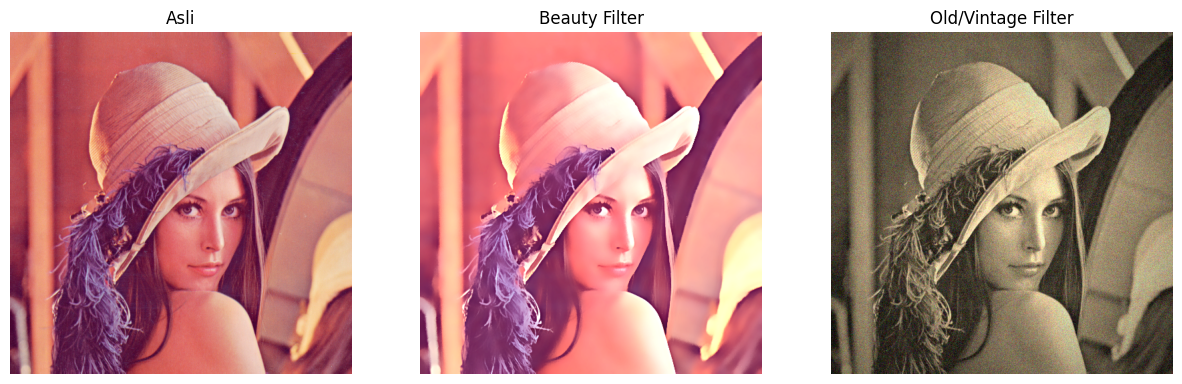

In [9]:
# 1. Beauty Filter
smooth = cv.bilateralFilter(img_lena, d=15, sigmaColor=75, sigmaSpace=75)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened_b = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
beauty = cv.convertScaleAbs(sharpened_b, alpha=1.2, beta=15)

# 2. Old/Vintage Filter
sepia_kernel = np.array([
    [0.272, 0.534, 0.131],
    [0.349, 0.686, 0.168],
    [0.393, 0.769, 0.189]
])
sepia = cv.transform(img_lena, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

rows, cols = img_lena.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel_vignette = kernel_y * kernel_x.T
mask_v = kernel_vignette / kernel_vignette.max()

vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask_v

noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side(
    [img_lena, beauty, old_img],
    ["Asli", "Beauty Filter", "Old/Vintage Filter"]
)

Percobaan 5: Anime / Cartoon Filter

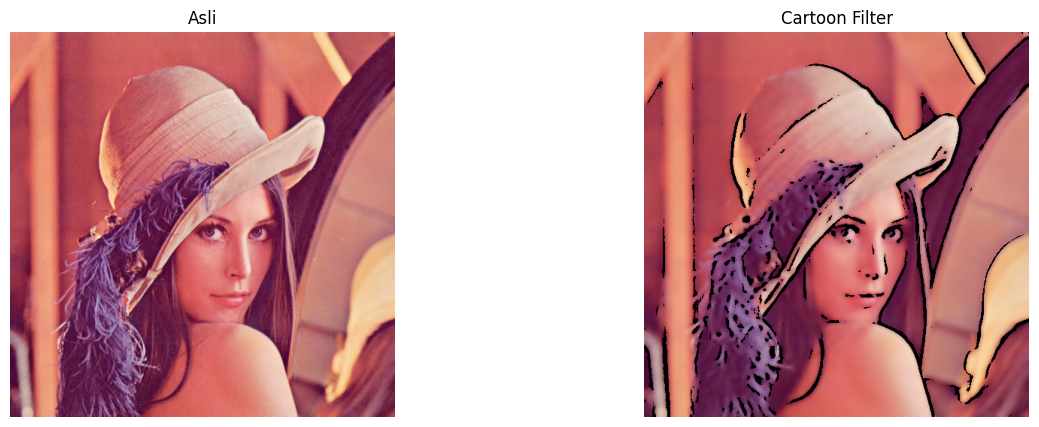

In [10]:
# Step 1: Edge detection (median blur + adaptive threshold)
gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(
    gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9
)

# Step 2: Bilateral Filter untuk perataan warna
color = cv.bilateralFilter(img_lena, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Penggabungan (Edge masking)
edges_colored = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
cartoon = cv.bitwise_and(color, edges_colored)

show_side_by_side([img_lena, cartoon], ["Asli", "Cartoon Filter"])

Percobaan 6: Night Filter & Night Glow

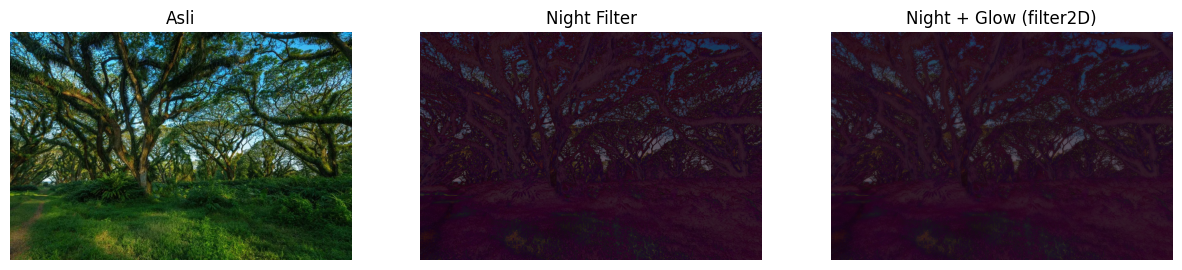

In [15]:
img = cv.imread("/content/drive/MyDrive/Kuliah/PCVK/Images/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan citra
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias warna biru (Blue Tint)
blue_tint = np.full_like(night, (50, 0, 100)) # Format BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang menggunakan filter2D
kernel_glow = np.ones((15, 15), np.float32) / 225.0
glow = cv.filter2D(night, -1, kernel_glow)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side(
    [img, night, night_glow],
    ["Asli", "Night Filter", "Night + Glow (filter2D)"]
)

Percobaan 7: Filter Suasana Pagi dan Kabut

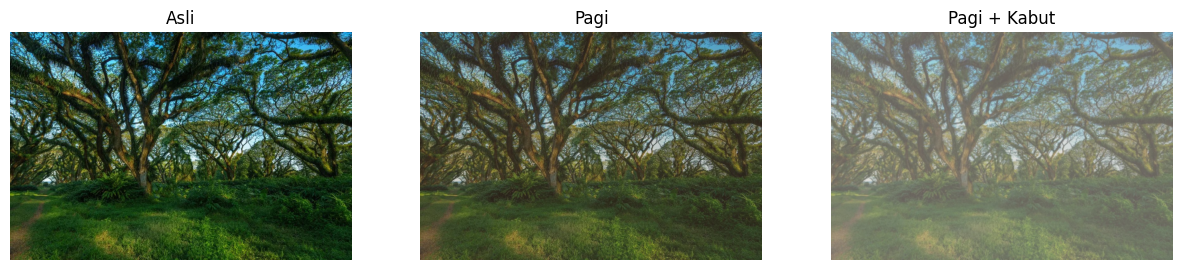

In [16]:
# Step 1: Penyesuaian kontras dan brightness
soft = cv.convertScaleAbs(img, alpha=0.9, beta=20)

# Step 2: Tambahkan warm tone
warm_tint = np.full_like(soft, (40, 70, 120)) # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Penambahan haze/kabut tipis
k_gauss = cv.getGaussianKernel(3, 3)
kernel_haze = k_gauss @ k_gauss.T
kabut = cv.filter2D(pagi, -1, kernel_haze)

white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["Asli", "Pagi", "Pagi + Kabut"])

**TUGAS PRAKTIKUM**

1. Tugas Analisis: Perbandingan Mean Filter vs. Median Filter pada Noise Salt and Pepper

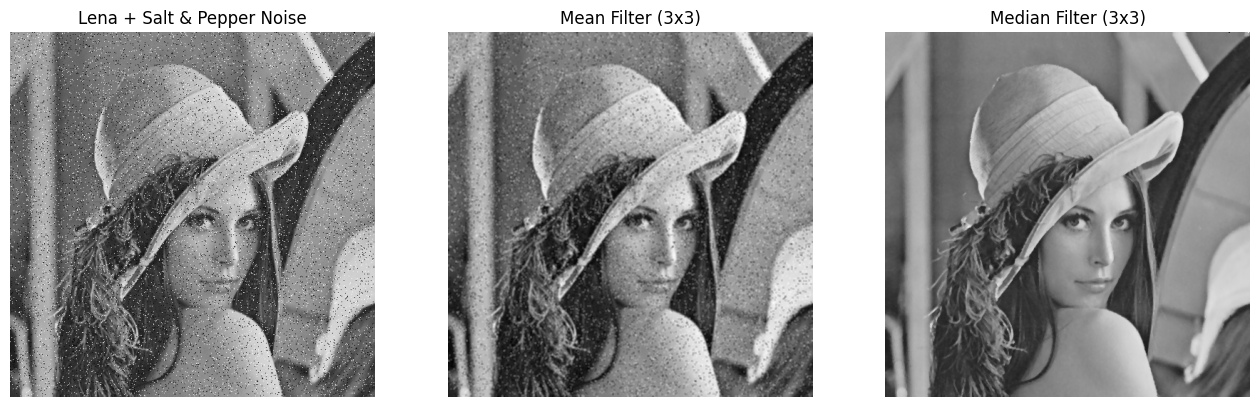

In [21]:
# 1. Load citra Lena dan ubah ke Grayscale
img_lena = cv.imread('/content/drive/MyDrive/Kuliah/PCVK/Images/Lenna.png')
if img_lena is None:
    # Alternatif jika path berbeda
    img_lena = cv.imread('Lenna.png')

lena_gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)

# a. Tambahkan noise bintik hitam-putih (Salt and Pepper) ke citra Lena
def add_salt_and_pepper_noise(image, salt_prob=0.03, pepper_prob=0.03):
    noisy_image = image.copy()

    # Tambah noise putih (Salt = 255)
    num_salt = np.ceil(salt_prob * image.size)
    coords_salt = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy_image[tuple(coords_salt)] = 255

    # Tambah noise hitam (Pepper = 0)
    num_pepper = np.ceil(pepper_prob * image.size)
    coords_pepper = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy_image[tuple(coords_pepper)] = 0

    return noisy_image

noisy_lena = add_salt_and_pepper_noise(lena_gray, salt_prob=0.03, pepper_prob=0.03)

# b. Terapkan Mean Filter (3x3) dan Median Filter (3x3)
mean_filtered = cv.blur(noisy_lena, (3, 3))
median_filtered = cv.medianBlur(noisy_lena, 3)

# Menampilkan hasil visual secara berdampingan
show_side_by_side(
    [noisy_lena, mean_filtered, median_filtered],
    ["Lena + Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"],
    figsize=(16, 5)
)

Analisis Hasil Visual

- Kinerja Mean Filter (Linear):Mean Filter bekerja dengan menjumlahkan seluruh intensitas piksel di dalam jendela tetangga berukuran $3\times3$ lalu membaginya dengan 9 (rata-rata aritmatika). Karena piksel derau salt bernilai sangat tinggi (255) dan pepper bernilai ekstrem rendah (0), nilai-nilai ekstrem tersebut ikut dihitung ke dalam rata-rata. Akibatnya, derau tidak hilang melainkan menyebar (blur) ke piksel di sekitarnya dan meninggalkan bercak buram (smudge) kelabu yang tetap mengganggu visual wajah Lena.
- Kinerja Median Filter (Non-linear):Median Filter mengurutkan kesembilan nilai piksel tetangga dari terkecil hingga terbesar, lalu mengambil nilai median (nilai tengahnya). Derau salt dan pepper selalu berada di urutan paling ujung (ujung terkecil untuk 0 dan ujung terbesar untuk 255). Karena nilai tengah yang terpilih hampir pasti merupakan intensitas asli dari kulit atau latar belakang Lena, derau ekstrem berhasil disaring dan dibuang sepenuhnya tanpa mengaburkan ketajaman tepi citra secara signifikan.

2. Tugas Evaluasi: Pemilihan Ukuran Kernel Sharpening ($3\times3$ vs $5\times5$)

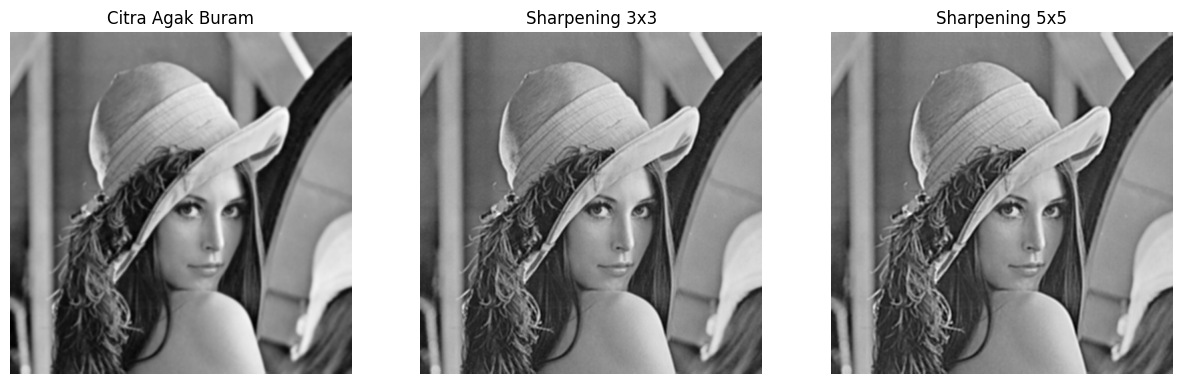

In [20]:
# a. Membuat kernel penajaman 3x3 dan 5x5
kernel_sharp_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

kernel_sharp_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32) / 8.0

# b. Menerapkan pada citra yang sedikit buram
blurry_img = cv.GaussianBlur(img_lena_gray, (5, 5), 1.5)
sharp_3 = cv.filter2D(blurry_img, -1, kernel_sharp_3x3)
sharp_5 = cv.filter2D(blurry_img, -1, kernel_sharp_5x5)

show_side_by_side(
    [blurry_img, sharp_3, sharp_5],
    ["Citra Agak Buram", "Sharpening 3x3", "Sharpening 5x5"]
)

Evaluasi & Rekomendasi:
- Kejelasan Tepi vs. Derau: Kernel $3\times3$ mempertegas tepi lokal dengan tetap mempertahankan tekstur alami dan menjaga kadar noise tetap rendah. Sebaliknya, kernel $5\times5$ meningkatkan amplitudo kontras secara agresif pada radius yang lebih luas, sehingga rentan memunculkan artefak cincin (ringing/halo effect) dan memperkuat high-frequency noise.
- Keputusan: Kernel $3\times3$ adalah yang paling optimal dan seimbang untuk penggunaan sehari-hari.

3. Tugas Kreasi: Filter Kartun Sederhana

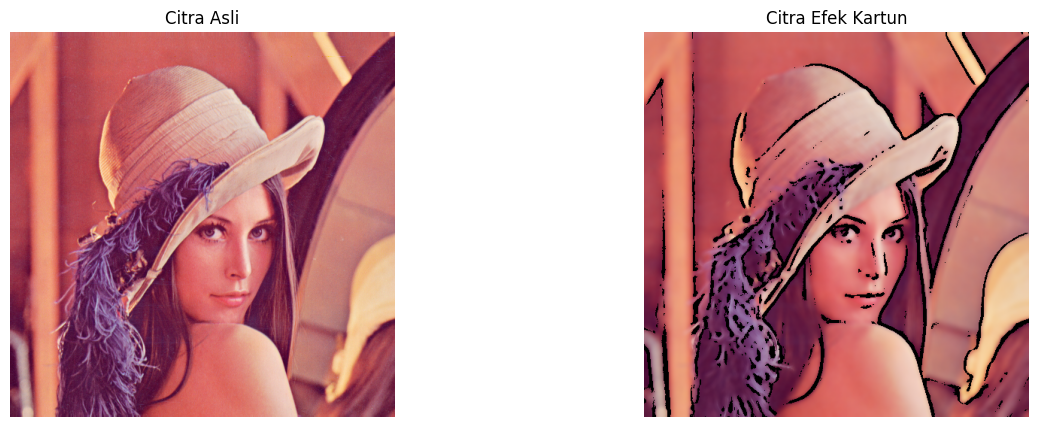

In [19]:
def kartun(image):
    # 1. Penghalusan warna menggunakan Bilateral Filter
    color = cv.bilateralFilter(image, d=9, sigmaColor=150, sigmaSpace=150)

    # 2. Deteksi garis tepi dengan Median Blur + Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(
        gray_blur, 255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        blockSize=9,
        C=7
    )

    # Konversi mask tepi ke format 3-channel (BGR)
    edges_colored = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)

    # 3. Penggabungan menggunakan operasi logika AND
    cartoon_img = cv.bitwise_and(color, edges_colored)
    return cartoon_img

# Eksekusi fungsi kustom kartun
hasil_kartun = kartun(img_lena)
show_side_by_side([img_lena, hasil_kartun], ["Citra Asli", "Citra Efek Kartun"])